# Baku Utility Hotline — Call Centre Workforce Planning
**Daily Data Analytics Project · Day 12**

## Business question
*A Baku utility company runs a customer hotline (08:00–20:00, 7 days a week) for billing, payments, outages, meter readings and new connections. Management reports that the centre "meets the 80/20 target" (80% of calls answered within 20 seconds), yet customers complain about long waits on Monday mornings and at weekends. **Where and why is the service level missed, how many agents are really needed in each half-hour, and and how much of the gap can a better shift pattern close with the same paid hours?***

Approach:
1. Clean 10 weeks of call-level data (27 Jul – 4 Oct 2026) and the half-hourly roster.
2. KPIs: service level, abandonment, ASA, AHT, occupancy — overall and per interval.
3. EDA: intraday × weekday demand, billing cycle, outage incidents, handle time by reason, caller patience.
4. **Queueing theory:** Erlang C written from scratch, checked against actual interval results.
5. **Forecast** half-hourly calls for a hold-out week (log-linear daily model × intraday profile).
6. **Staffing requirement** per interval (Erlang C, 80/20, occupancy ≤ 90%, grossed up for shrinkage).
7. **Shift scheduling as a MILP** (SciPy `milp`): minimum paid hours covering the requirement.
8. **Simulation:** replay the hold-out week's real calls through a queue simulator with three rosters: current, optimised for 80/20 (more hours) and the same hours re-shaped.

> Data is **synthetic** (fixed seed), generated by `data/generate_data.py`.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from matplotlib.ticker import PercentFormatter
import wfm
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.edgecolor": "#898781", "axes.titleweight": "bold"})
BLUE, ORANGE, AQUA, YELLOW, GREY, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#898781", "#d03b3b"
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
L = wfm.LABELS
COST_PER_HOUR = 9.0   # AZN, fully loaded agent-hour (assumption)
pd.set_option("display.float_format", "{:,.3f}".format)
calls_raw, roster_raw = wfm.load_raw()
print(calls_raw.shape, roster_raw.shape); calls_raw.head()

(177346, 6) (1680, 4)


,call_id,arrival_ts,reason,wait_sec,abandoned,handle_sec
0,C0000001,2026-07-27 08:00:40,billing,0,0,143.000
1,C0000002,2026-07-27 08:00:55,meter_reading,0,0,160.000
2,C0000003,2026-07-27 08:01:44,billing,0,0,197.000
3,C0000004,2026-07-27 08:02:37,new_connection,0,0,221.000
4,C0000005,2026-07-27 08:02:42,payment,0,0,79.000


## 1. Data quality check

In [2]:
df, roster, log = wfm.clean(calls_raw, roster_raw)
ans = df[df.abandoned == 0]
checks = {**log,
 "Date range": f"{df.date.min():%Y-%m-%d} → {df.date.max():%Y-%m-%d} ({df.date.nunique()} days)",
 "Duplicate call_id after cleaning": int(df.call_id.duplicated().sum()),
 "Abandoned calls with a handle time": int((df.abandoned.eq(1) & df.handle_sec.notna()).sum()),
 "Negative waits": int((df.wait_sec < 0).sum()),
 "Roster rows / days with 24 intervals": f"{len(roster):,} / {(roster.groupby('date').size() == 24).sum()}",
 "Intervals with logged-in > scheduled": int((roster.logged_in_agents > roster.scheduled_agents).sum()),
}
pd.Series(checks).to_frame("result")

,result
Rows in,177346
Exact duplicate rows dropped,110
Test / out-of-hours calls dropped,28
Impossible handle times (<10 s or >3 h) set to missing,48
Missing reason -> 'unknown',2658
Rows out,177208
Date range,2026-07-27 → 2026-10-04 (70 days)
Duplicate call_id after cleaning,0
Abandoned calls with a handle time,0
Negative waits,0


Fixes: 110 exact duplicate rows (an export re-run) dropped; 28 system test calls made before opening or after closing removed; 47 answered calls with impossible handle times (zero, negative, or 4–9 hours from agents who never closed the call) set to missing so they don't distort AHT; 1.5% of calls with no IVR reason labelled `unknown`. The roster is complete: 70 days × 24 half-hours.

## 2. Headline KPIs

In [3]:
st = wfm.interval_stats(df).reset_index().merge(roster[["date", "interval", "scheduled_agents", "logged_in_agents"]],
                                             on=["date", "interval"])
st["dow"] = st.date.dt.dayofweek
sl_all = df.in_sl.sum() / (~df.short_abandon).sum()
occ = ans.handle_sec.sum() / (roster.logged_in_agents.sum() * wfm.IV)
miss = (st.sl < 0.8).mean()
K = {
 "Calls offered": f"{len(df):,} ({len(df) / df.date.nunique():,.0f} per day)",
 "Service level (answered ≤ 20 s, excl. abandons < 5 s)": f"{sl_all:.1%}",
 "Abandon rate (all / excl. < 5 s)": f"{df.abandoned.mean():.1%} / {(df.abandoned.eq(1) & ~df.short_abandon).sum() / (~df.short_abandon).sum():.1%}",
 "Average speed of answer (answered calls)": f"{ans.wait_sec.mean():.1f} s (P90 {ans.wait_sec.quantile(.9):.0f} s)",
 "Average handle time (AHT)": f"{ans.handle_sec.mean():.0f} s",
 "Agent occupancy (handle time / logged-in time)": f"{occ:.1%}",
 "Half-hours missing 80/20": f"{miss:.1%} of {len(st):,}",
 "Calls arriving in half-hours below 80/20": f"{st.loc[st.sl < .8, 'offered'].sum() / st.offered.sum():.1%}",
 "Shrinkage (1 − logged-in / scheduled)": f"{1 - roster.logged_in_agents.sum() / roster.scheduled_agents.sum():.1%}",
 "Scheduled agent-hours per week": f"{roster.scheduled_agents.sum() / 2 / 10:,.0f} (≈ AZN {roster.scheduled_agents.sum() / 2 / 10 * COST_PER_HOUR:,.0f})",
}
pd.Series(K).to_frame("value")

,value
Calls offered,"177,208 (2,532 per day)"
"Service level (answered ≤ 20 s, excl. abandons < 5 s)",80.8%
Abandon rate (all / excl. < 5 s),8.2% / 6.2%
Average speed of answer (answered calls),9.0 s (P90 35 s)
Average handle time (AHT),252 s
Agent occupancy (handle time / logged-in time),72.7%
Half-hours missing 80/20,"33.4% of 1,680"
Calls arriving in half-hours below 80/20,33.8%
Shrinkage (1 − logged-in / scheduled),20.7%
Scheduled agent-hours per week,"1,980 (≈ AZN 17,820)"


In [4]:
by_day = df.groupby("dow").apply(lambda g: pd.Series({
    "calls_per_day": len(g) / g.date.nunique(), "service_level": g.in_sl.sum() / (~g.short_abandon).sum(),
    "abandon_rate": g.abandoned.mean(), "asa_sec": g.loc[g.abandoned == 0, "wait_sec"].mean()}))
by_day.index = DAYS
by_day.style.format({"calls_per_day": "{:,.0f}", "service_level": "{:.1%}", "abandon_rate": "{:.1%}", "asa_sec": "{:.1f}"})

,calls_per_day,service_level,abandon_rate,asa_sec
Mon,"3,269",79.9%,7.9%,9.0
Tue,"3,281",76.3%,10.1%,11.3
Wed,"2,763",90.0%,3.9%,4.1
Thu,"2,774",89.2%,4.3%,4.7
Fri,"2,632",91.1%,3.6%,3.7
Sat,"1,719",60.7%,17.7%,21.6
Sun,"1,283",60.9%,18.2%,22.0


The 81% headline hides two different centres: Wednesday–Friday run at ~90%, while **Monday–Tuesday sit at 76–80% and weekends at ~61%**. A quarter of all half-hours miss the target.

## 3. Exploratory analysis

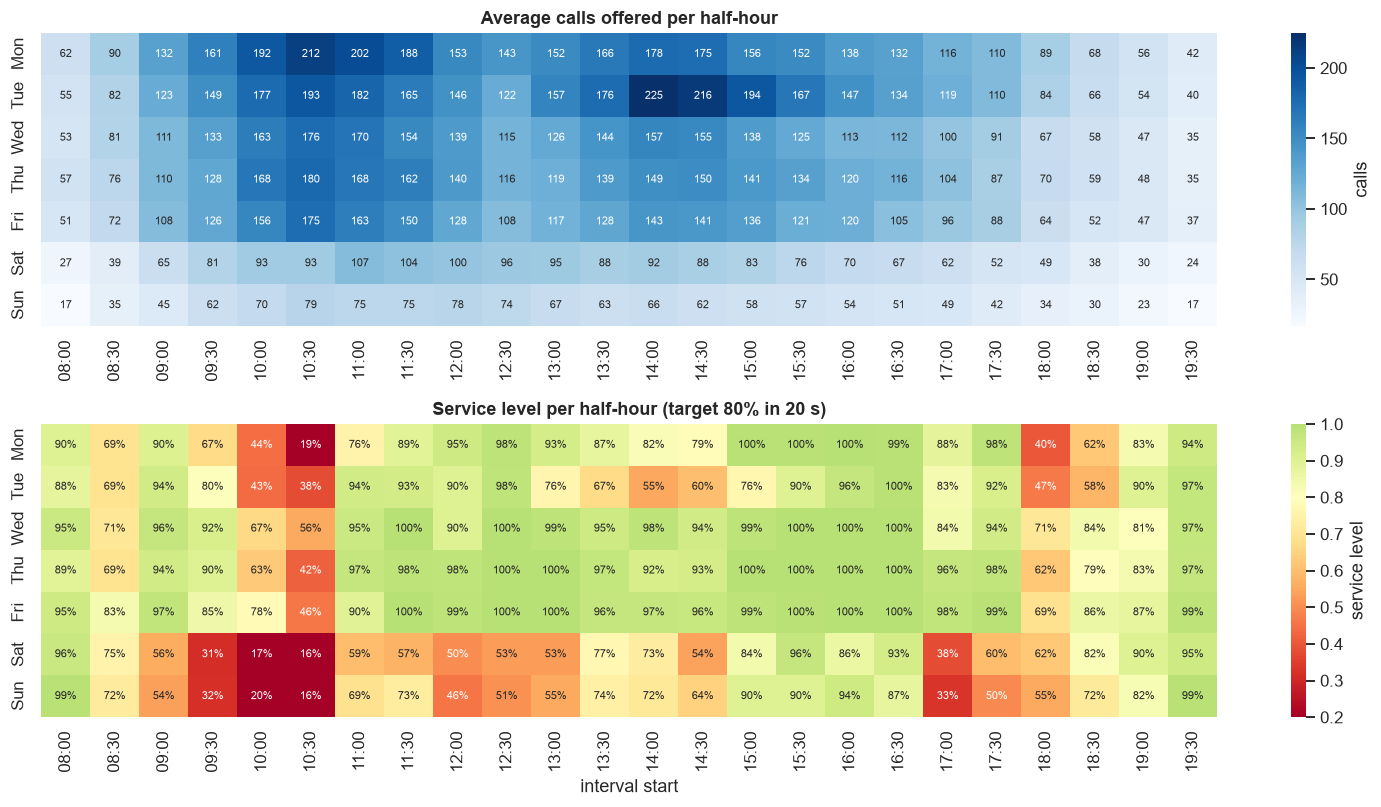

In [5]:
vol = df.groupby(["dow", "interval"]).size().unstack() / df.groupby("dow").date.nunique().values[:, None]
slp = st.groupby(["dow", "interval"]).apply(lambda g: g.in_sl.sum() / (g.offered - g.short_ab).sum()).unstack()
fig, ax = plt.subplots(2, 1, figsize=(14, 7.5))
sns.heatmap(vol, ax=ax[0], cmap="Blues", annot=True, fmt=".0f", annot_kws={"size": 7}, cbar_kws={"label": "calls"},
            xticklabels=L, yticklabels=DAYS)
ax[0].set_title("Average calls offered per half-hour"); ax[0].set_xlabel("")
sns.heatmap(slp, ax=ax[1], cmap="RdYlGn", vmin=0.2, vmax=1, center=0.8, annot=True, fmt=".0%", annot_kws={"size": 7},
            cbar_kws={"label": "service level"}, xticklabels=L, yticklabels=DAYS)
ax[1].set_title("Service level per half-hour (target 80% in 20 s)"); ax[1].set_xlabel("interval start")
for a in ax: a.set_ylabel("")
plt.tight_layout(); plt.savefig("images/eda_heatmaps.png", bbox_inches="tight"); plt.show()

Demand peaks 10:00–11:30 on weekdays (Monday ~20% above midweek), while the service-level map shows **red exactly where demand peaks before the 11:00 shift arrives**, and again at 18:00 when the 09:00–18:00 shift leaves. At 12:00–15:00 lunch breaks pull Monday/Tuesday down. Weekends are under-staffed almost all day.

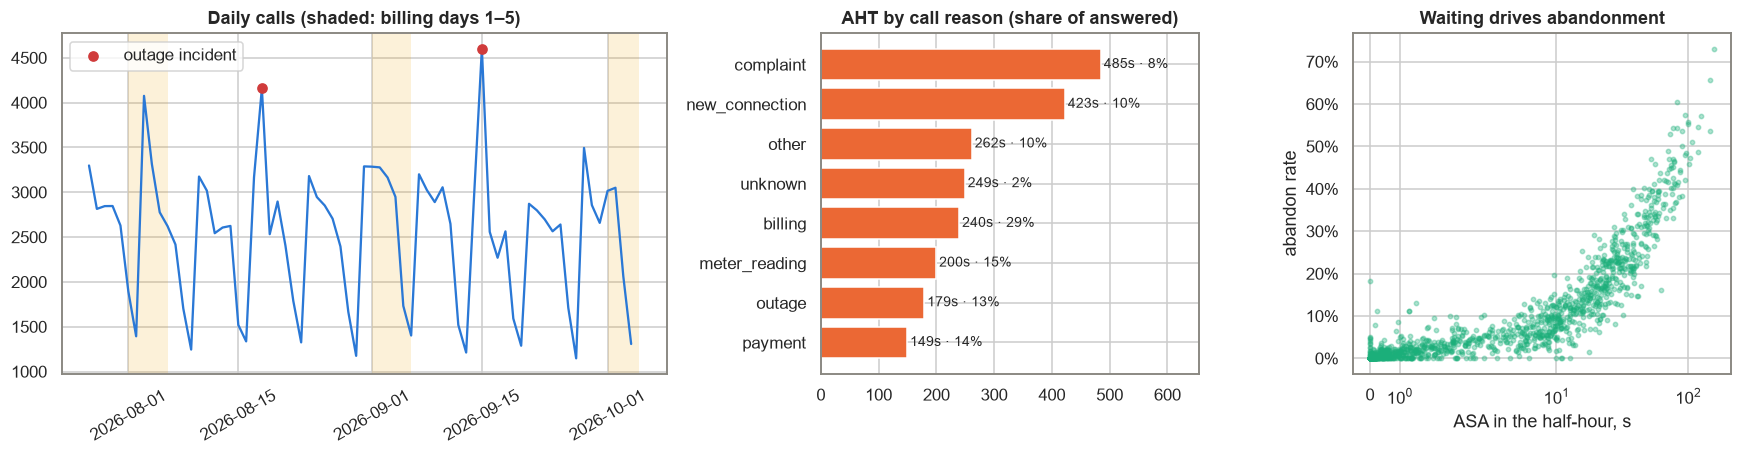

Incident days: ['2026-09-15', '2026-08-18']


In [6]:
daily = df.groupby("date").size()
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3), gridspec_kw={"width_ratios": [1.6, 1, 1]})
a = ax[0]; a.plot(daily.index, daily.values, color=BLUE, lw=1.5)
for d in daily.index[daily.index.day <= 5]: a.axvspan(d, d + pd.Timedelta(days=1), color=YELLOW, alpha=.15, lw=0)
inc = daily[daily > daily.rolling(7, center=True, min_periods=1).median() * 1.3]
inc = inc[inc.index.dayofweek < 5].nlargest(2)
a.scatter(inc.index, inc.values, color=RED, zorder=3, label="outage incident")
a.set_title("Daily calls (shaded: billing days 1–5)"); a.legend(loc="upper left"); a.tick_params(axis="x", rotation=30)
aht = ans.groupby("reason").handle_sec.agg(["mean", "size"]).sort_values("mean")
ax[1].barh(aht.index, aht["mean"], color=ORANGE)
for y, (m, n) in enumerate(aht.values): ax[1].text(m + 5, y, f"{m:.0f}s · {n / len(ans):.0%}", va="center", fontsize=9)
ax[1].set_title("AHT by call reason (share of answered)"); ax[1].set_xlim(0, aht["mean"].max() * 1.35)
w = st.assign(ab=st.abandoned / st.offered)
asa_i = df[df.abandoned == 0].groupby(["date", "interval"]).wait_sec.mean().rename("asa")
w = w.merge(asa_i, left_on=["date", "interval"], right_index=True)
ax[2].scatter(w.asa, w.ab, s=8, alpha=.35, color=AQUA)
ax[2].set_xscale("symlog", linthresh=5); ax[2].yaxis.set_major_formatter(PercentFormatter(1, 0))
ax[2].set_xlabel("ASA in the half-hour, s"); ax[2].set_ylabel("abandon rate"); ax[2].set_title("Waiting drives abandonment")
plt.tight_layout(); plt.savefig("images/eda_patterns.png", bbox_inches="tight"); plt.show()
print("Incident days:", [f"{d:%Y-%m-%d}" for d in inc.index])

In [7]:
# Caller patience: exponential MLE with censoring (answered calls are censored at their wait)
long = df[~df.short_abandon]
mean_patience = long.wait_sec.sum() / long.abandoned.sum()
bill = df.groupby("date").size().to_frame("calls").assign(dow=lambda x: x.index.dayofweek, dom=lambda x: x.index.day)
bill = bill[~bill.index.isin(inc.index)]
bill["ratio"] = bill.calls / bill.groupby("dow").calls.transform("median")
print(f"Estimated mean caller patience: {mean_patience:.0f} s  |  immediate (<5 s) abandons: {df.short_abandon.mean():.1%} of calls")
bill.groupby(pd.cut(bill.dom, [0, 5, 10, 31], labels=["days 1-5", "days 6-10", "days 11+"]), observed=True).ratio.mean().to_frame("volume vs weekday median")

Estimated mean caller patience: 178 s  |  immediate (<5 s) abandons: 2.1% of calls


,volume vs weekday median
dom,
days 1-5,1.116
days 6-10,1.007
days 11+,0.970


Three demand drivers a planner has to respect: the **billing cycle** (days 1–5 bring ~10% more calls than the rest of the month), **outage incidents** (two weekday afternoons with +1,100 and +1,600 extra calls) and the **weekday shape**. Complaints and new connections take 7–8 minutes, payments 2.5. Callers wait on average about 3 minutes before hanging up, so abandonment explodes once ASA passes ~30 s.

## 4. Queueing model: Erlang C

In [8]:
# Erlang C curve for an average Monday 10:30 half-hour
mon = st[(st.dow == 0) & (st.interval == 5)]
c_mon = mon.offered.mean(); aht_all = ans.handle_sec.mean()
Ns = np.arange(18, 41)
curve = pd.DataFrame({"agents": Ns,
    "service_level": [wfm.service_level(c_mon, aht_all, n) for n in Ns],
    "asa_sec": [wfm.asa(c_mon, aht_all, n) for n in Ns],
    "occupancy": [min(c_mon * aht_all / wfm.IV / n, 1) for n in Ns]})
n_req = wfm.required_agents(c_mon, aht_all)
print(f"Monday 10:30: {c_mon:.0f} calls, AHT {aht_all:.0f}s → load {c_mon * aht_all / wfm.IV:.1f} erlangs; "
      f"logged in on average {mon.logged_in_agents.mean():.1f}; Erlang C needs {n_req} for 80/20")
curve[curve.agents.between(n_req - 5, n_req + 3)].style.format({"service_level": "{:.1%}", "asa_sec": "{:.1f}", "occupancy": "{:.1%}"}).hide()

Monday 10:30: 212 calls, AHT 252s → load 29.8 erlangs; logged in on average 20.3; Erlang C needs 35 for 80/20


agents,service_level,asa_sec,occupancy
30,6.1%,1146.6,99.3%
31,30.9%,158.5,96.1%
32,49.9%,68.2,93.1%
33,64.1%,36.4,90.3%
34,74.6%,21.2,87.6%
35,82.4%,12.9,85.1%
36,87.9%,8.0,82.7%
37,91.9%,5.0,80.5%
38,94.6%,3.2,78.4%


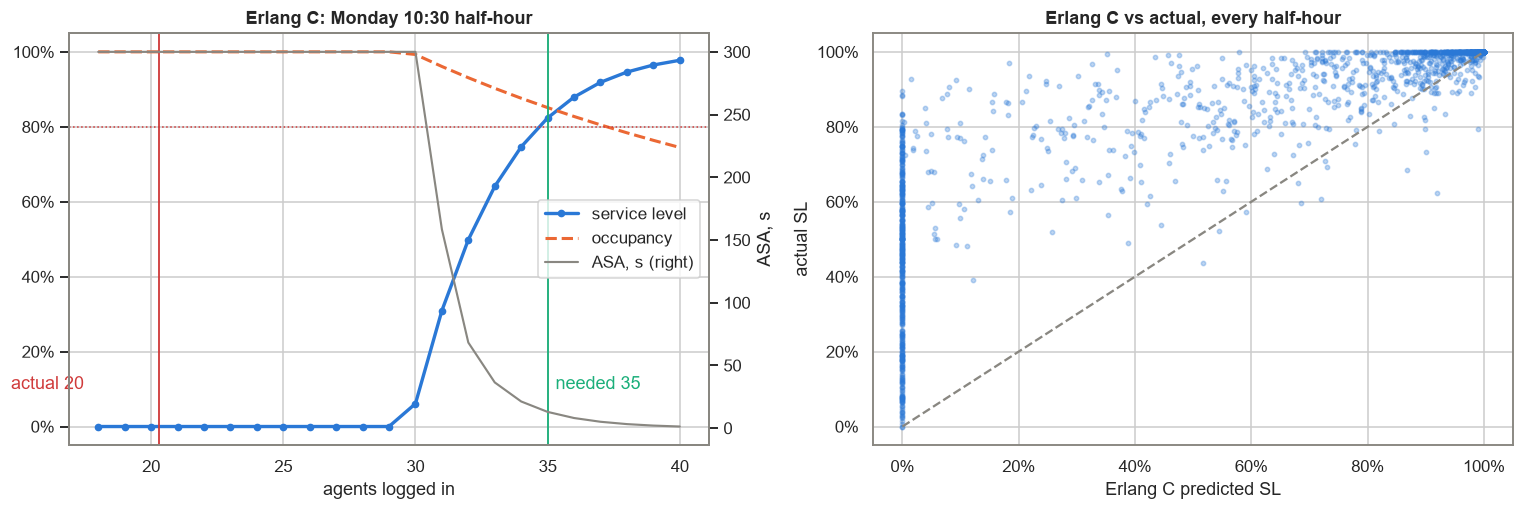

Erlang C ≥ 80%: mean |error| 3.5%;  below 80%: Erlang C 23.7% vs actual 62.7%


In [9]:
aht_i = ans.groupby(["date", "interval"]).handle_sec.mean().rename("aht")
v = st.merge(aht_i, left_on=["date", "interval"], right_index=True)
v["erlang_sl"] = [wfm.service_level(c, a, n) for c, a, n in zip(v.offered, v.aht, v.logged_in_agents)]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
a = ax[0]; a2 = a.twinx()
a.plot(curve.agents, curve.service_level, color=BLUE, lw=2.2, marker="o", ms=4, label="service level")
a.plot(curve.agents, curve.occupancy, color=ORANGE, lw=2, ls="--", label="occupancy")
a2.plot(curve.agents, curve.asa_sec.clip(upper=300), color=GREY, lw=1.4, label="ASA, s (right)")
a.axhline(.8, color=RED, lw=1, ls=":"); a.axvline(n_req, color=AQUA, lw=1.2)
a.axvline(mon.logged_in_agents.mean(), color=RED, lw=1.2)
a.text(n_req + .3, .1, f"needed {n_req}", color=AQUA); a.text(mon.logged_in_agents.mean() - 5.6, .1, f"actual {mon.logged_in_agents.mean():.0f}", color=RED)
a.yaxis.set_major_formatter(PercentFormatter(1, 0)); a.set_xlabel("agents logged in"); a.set_title("Erlang C: Monday 10:30 half-hour")
h1, l1 = a.get_legend_handles_labels(); h2, l2 = a2.get_legend_handles_labels(); a.legend(h1 + h2, l1 + l2, loc="center right")
a2.set_ylabel("ASA, s"); a2.grid(False)
ax[1].scatter(v.erlang_sl, v.sl, s=8, alpha=.3, color=BLUE)
ax[1].plot([0, 1], [0, 1], color=GREY, ls="--"); ax[1].set_xlabel("Erlang C predicted SL"); ax[1].set_ylabel("actual SL")
ax[1].set_title("Erlang C vs actual, every half-hour")
for x in (ax[1].xaxis, ax[1].yaxis): x.set_major_formatter(PercentFormatter(1, 0))
plt.tight_layout(); plt.savefig("images/erlang_c.png", bbox_inches="tight"); plt.show()
ok = v.erlang_sl >= .8
print(f"Erlang C ≥ 80%: mean |error| {np.abs(v.erlang_sl - v.sl)[ok].mean():.1%};  below 80%: Erlang C {v.erlang_sl[~ok].mean():.1%} vs actual {v.sl[~ok].mean():.1%}")

Erlang C tracks reality well when the centre is adequately staffed, and is **pessimistic when it is under-staffed**: it assumes nobody hangs up, but in real life abandoning callers shorten the queue for the rest. That makes it a slightly conservative planning tool — the standard choice for setting agent counts — while the simulator in section 7 handles abandonment explicitly.

## 5. Forecasting the hold-out week (28 Sep – 4 Oct)

In [10]:
HOLD = pd.Timestamp("2026-09-28")
dd = df.groupby("date").size().rename("calls").to_frame()
dd["dow"], dd["dom"] = dd.index.dayofweek, dd.index.day
dd["t"] = (dd.index - dd.index.min()).days / 7
dd["b1"], dd["b2"] = (dd.dom <= 5).astype(float), dd.dom.between(6, 10).astype(float)
def X(d): return np.column_stack([np.eye(7)[d.dow], d.b1, d.b2, d.t])
train = dd[(dd.index < HOLD) & ~dd.index.isin(inc.index)]; test = dd[dd.index >= HOLD]
beta, *_ = np.linalg.lstsq(X(train), np.log(train.calls), rcond=None)
resid = np.log(train.calls) - X(train) @ beta
test = test.assign(fc=np.exp(X(test) @ beta + resid.var() / 2),
                   naive=dd.calls.shift(7).loc[test.index])
print(f"Billing uplift days 1-5: {np.exp(beta[7]) - 1:+.1%}, days 6-10: {np.exp(beta[8]) - 1:+.1%}, weekly trend: {np.exp(beta[9]) - 1:+.2%}")
tr_calls = df[(df.date < HOLD) & ~df.date.isin(inc.index)]
prof = tr_calls.assign(we=tr_calls.dow >= 5).groupby(["we", "interval"]).size()
prof = prof / prof.groupby(level=0).transform("sum")
aht_prof = tr_calls[tr_calls.abandoned == 0].assign(we=lambda x: x.dow >= 5).groupby(["we", "interval"]).handle_sec.mean()
hi = st[st.date >= HOLD].copy()
hi["fc"] = [test.fc[d] * prof[(d.dayofweek >= 5, i)] for d, i in zip(hi.date, hi.interval)]
hi["naive"] = st.set_index(["date", "interval"]).offered.reindex(list(zip(hi.date - pd.Timedelta(days=7), hi.interval))).values
hi["fc_aht"] = [aht_prof[(d.dayofweek >= 5, i)] for d, i in zip(hi.date, hi.interval)]
wape = lambda a, f: np.abs(a - f).sum() / a.sum()
pd.DataFrame({"daily WAPE": [wape(test.calls, test.fc), wape(test.calls, test.naive)],
              "half-hourly WAPE": [wape(hi.offered, hi.fc), wape(hi.offered, hi.naive)]},
             index=["log-linear × intraday profile", "naive: same day last week"]).style.format("{:.1%}")

Billing uplift days 1-5: +14.8%, days 6-10: +3.7%, weekly trend: -0.34%


,daily WAPE,half-hourly WAPE
log-linear × intraday profile,5.2%,9.7%
naive: same day last week,11.4%,15.5%


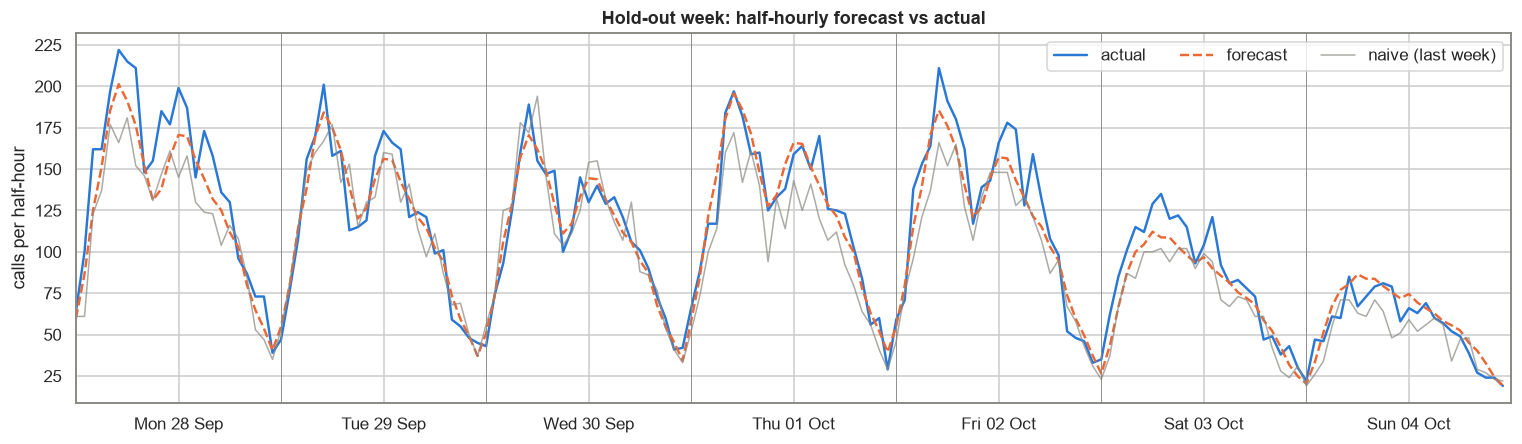

In [11]:
fig, ax = plt.subplots(figsize=(14, 4.2))
x = np.arange(len(hi))
ax.plot(x, hi.offered, color=BLUE, lw=1.6, label="actual")
ax.plot(x, hi.fc, color=ORANGE, lw=1.6, ls="--", label="forecast")
ax.plot(x, hi.naive, color=GREY, lw=1, alpha=.7, label="naive (last week)")
ax.set_xticks(np.arange(0, len(hi), 24) + 12, [f"{d:%a %d %b}" for d in test.index]); ax.set_xlim(0, len(hi))
for b in range(24, len(hi), 24): ax.axvline(b, color=GREY, lw=.6)
ax.set_ylabel("calls per half-hour"); ax.set_title("Hold-out week: half-hourly forecast vs actual"); ax.legend(ncol=3)
plt.tight_layout(); plt.savefig("images/forecast.png", bbox_inches="tight"); plt.show()

The naive "same day last week" forecast misses the billing cycle (1–4 October are billing days, the previous week was not), so it is systematically low. The log-linear model learns the weekday pattern, the billing uplift and the slow trend, and cuts the error substantially.

## 6. Staffing requirement per half-hour

In [12]:
ratio = roster.logged_in_agents.sum() / roster.scheduled_agents.sum()
hi["req_net"] = [wfm.required_agents(c, a) for c, a in zip(hi.fc, hi.fc_aht)]
hi["req_sched"] = np.ceil(hi.req_net / ratio).astype(int)
hi["gap"] = hi.scheduled_agents - hi.req_sched
print(f"Gross-up for shrinkage: scheduled = net / {ratio:.3f}")
g = hi.groupby(hi.date.dt.strftime("%a %d %b"), sort=False).agg(
    required_hours=("req_sched", lambda s: s.sum() / 2), scheduled_hours=("scheduled_agents", lambda s: s.sum() / 2),
    short_intervals=("gap", lambda s: (s < 0).sum()), over_hours=("gap", lambda s: s.clip(lower=0).sum() / 2),
    under_hours=("gap", lambda s: -s.clip(upper=0).sum() / 2))
g.loc["Week"] = g.sum(); g

Gross-up for shrinkage: scheduled = net / 0.793


,required_hours,scheduled_hours,short_intervals,over_hours,under_hours
date,,,,,
Mon 28 Sep,350.000,342.000,11.000,26.500,34.500
Tue 29 Sep,324.000,342.000,7.000,41.000,23.000
Wed 30 Sep,305.000,342.000,7.000,54.000,17.000
Thu 01 Oct,343.000,342.000,11.000,31.000,32.000
Fri 02 Oct,326.500,342.000,8.000,40.000,24.500
Sat 03 Oct,221.500,153.000,22.000,0.500,69.000
Sun 04 Oct,181.000,117.000,23.000,0.000,64.000
Week,"2,051.000","1,980.000",89.000,193.000,264.000


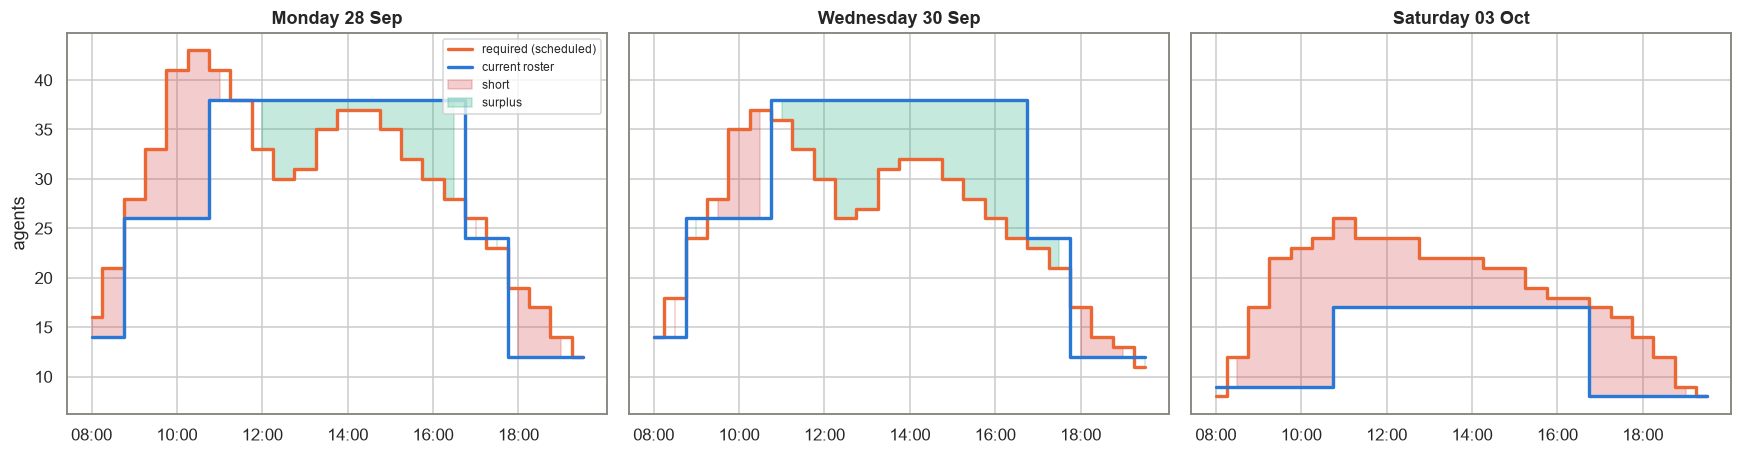

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3), sharey=True)
for a, d in zip(ax, [HOLD, HOLD + pd.Timedelta(days=2), HOLD + pd.Timedelta(days=5)]):
    h = hi[hi.date == d]
    a.step(range(24), h.req_sched, where="mid", color=ORANGE, lw=2.2, label="required (scheduled)")
    a.step(range(24), h.scheduled_agents, where="mid", color=BLUE, lw=2.2, label="current roster")
    a.fill_between(range(24), h.req_sched, h.scheduled_agents, step="mid", where=h.req_sched > h.scheduled_agents, color=RED, alpha=.25, label="short")
    a.fill_between(range(24), h.req_sched, h.scheduled_agents, step="mid", where=h.req_sched < h.scheduled_agents, color=AQUA, alpha=.25, label="surplus")
    a.set_xticks(range(0, 24, 4), L[::4]); a.set_title(f"{d:%A %d %b}")
ax[0].set_ylabel("agents"); ax[0].legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.savefig("images/staffing_gap.png", bbox_inches="tight"); plt.show()

The current roster is the same flat 08/09/11 pattern every weekday. It is **short in the morning ramp and at 18:00–19:00** and carries a **surplus in the afternoon**. On weekends it is short almost all day.

## 7. Optimised shift plan (MILP) and simulation

In [14]:
plans, new_sched, hours_new = [], {}, {}
for d in test.index:
    req = hi.loc[hi.date == d, "req_sched"].values
    plan, cov, hrs = wfm.schedule_milp(req, ft_len=16, pt_len=8, pt_max_share=0.30)
    plans.append(plan.assign(day=f"{d:%a}")); new_sched[d] = cov; hours_new[d] = hrs
plans = pd.concat(plans)
# Scenario B: keep the SAME weekly paid hours as today and only re-shape / move them between days
budget = hi.scheduled_agents.sum() / 2
cov_b, hrs_b = wfm.schedule_budget([hi.loc[hi.date == d, "req_sched"].values for d in test.index], budget)
same_sched = {d: cov_b[k] for k, d in enumerate(test.index)}
print(f"Scenario A: minimum hours to meet 80/20 = {sum(hours_new.values()):,.0f} h/week  |  Scenario B: same hours as today = {hrs_b:,.0f} h/week")
print("Shift templates: full-time 8 h, part-time 4 h (≤ 30% of hours), any half-hour start that ends by 20:00")
plans.pivot_table(index=["type", "start"], columns="day", values="agents", aggfunc="sum", sort=False).fillna(0).astype(int)[[f"{d:%a}" for d in test.index]]

Scenario A: minimum hours to meet 80/20 = 2,272 h/week  |  Scenario B: same hours as today = 1,980 h/week
Shift templates: full-time 8 h, part-time 4 h (≤ 30% of hours), any half-hour start that ends by 20:00


day         Mon  Tue  Wed  Thu  Fri  Sat  Sun
type start                                   
FT   08:00   10    8   10   11    9    5    4
     08:30    5    5    4    5    5    4    4
     09:30   11   11    8    9   10    5    4
     10:00    1    0    2    2    1    0    0
     10:30    2    3    2    2    3    1    1
     11:30    5    5    4    5    5    4    3
     11:00    0    0    0    0    0    2    2
PT   08:00    6    6    4    5    5    3    3
     10:00    1    0    1    1    0    1    0
     09:00    7    7    6    7    8    5    3
     14:00    3    3    2    2    2    1    0
     16:00   12   11   11   12   11    8    7

In [15]:
rng = np.random.default_rng(12)
SCEN = ["current", "optimised", "same-hours"]
cmp_rows, sl_int = [], {"actual": [], **{s: [] for s in SCEN}}
pool = ans[(ans.date < HOLD) & ans.handle_sec.notna()].groupby("reason").handle_sec
for k, d in enumerate(test.index):
    c = df[df.date == d]
    ab = c.abandoned.values == 1
    handle = c.handle_sec.values.copy()
    miss_h = np.isnan(handle)
    handle[miss_h] = [pool.get_group(r).sample(1, random_state=int(rng.integers(1e9))).iloc[0] if r in pool.groups else aht_all
                      for r in c.reason.values[miss_h]]
    patience = np.where(ab, c.wait_sec.values, c.wait_sec.values + rng.exponential(mean_patience, len(c)))
    agents = {"current": roster.loc[roster.date == d, "logged_in_agents"].values,
              "optimised": rng.binomial(new_sched[d], ratio), "same-hours": rng.binomial(same_sched[d], ratio)}
    row = {"day": f"{d:%a %d %b}", "calls": len(c), "SL actual": c.in_sl.sum() / (~c.short_abandon).sum(),
           "hours current": roster.loc[roster.date == d, "scheduled_agents"].sum() / 2,
           "hours optimised": hours_new[d], "hours same-hours": cov_b[k].sum() / 2}
    for s in SCEN:
        w, a = wfm.simulate_day(c.t.values, handle, patience, agents[s])
        sl_int[s].append(pd.Series(((~a) & (w <= 20)).astype(float)).groupby(c.interval.values).sum()
                         / pd.Series(~(a & (w < 5))).groupby(c.interval.values).sum())
        row[f"SL {s}"], row[f"abandon {s}"] = wfm.sl_from_sim(w, a), a.mean()
        row[f"bad intervals {s}"] = int((sl_int[s][-1] < .8).sum())
    sl_int["actual"].append(hi.loc[hi.date == d, "sl"].reset_index(drop=True))
    cmp_rows.append(row)
cmp = pd.DataFrame(cmp_rows).set_index("day")
tot = cmp.sum(numeric_only=True)
for col in cmp.columns:
    if col.startswith(("SL", "abandon")): tot[col] = (cmp[col] * cmp.calls).sum() / cmp.calls.sum()
cmp.loc["Week"] = tot
fmt = {c: "{:.1%}" for c in cmp.columns if c.startswith(("SL", "abandon"))} | {"calls": "{:,.0f}"} | \
      {c: "{:,.0f}" for c in cmp.columns if c.startswith(("hours", "bad"))}
cmp[["calls", "SL actual"] + [f"SL {s}" for s in SCEN] + [f"abandon {s}" for s in SCEN]].style.format(fmt)

,calls,SL actual,SL current,SL optimised,SL same-hours,abandon current,abandon optimised,abandon same-hours
day,,,,,,,,
Mon 28 Sep,"3,494",77.2%,77.3%,88.5%,83.0%,8.2%,4.0%,6.1%
Tue 29 Sep,"2,856",91.5%,91.7%,95.2%,88.5%,3.3%,1.5%,4.3%
Wed 30 Sep,"2,658",86.6%,86.5%,95.2%,83.4%,5.4%,2.1%,6.4%
Thu 01 Oct,"3,015",86.7%,86.7%,95.4%,91.0%,5.3%,1.6%,3.3%
Fri 02 Oct,"3,050",81.6%,81.5%,93.1%,79.5%,6.2%,2.4%,6.3%
Sat 03 Oct,"2,063",44.1%,42.7%,87.1%,76.6%,26.0%,5.6%,11.0%
Sun 04 Oct,"1,307",61.5%,61.2%,94.6%,76.0%,16.8%,1.8%,17.2%
Week,"18,443",78.2%,78.1%,92.7%,83.4%,8.8%,2.7%,6.8%


In [16]:
cmp[[f"hours {s}" for s in ["current", "optimised", "same-hours"]] + [f"bad intervals {s}" for s in SCEN]].style.format(fmt)

,hours current,hours optimised,hours same-hours,bad intervals current,bad intervals optimised,bad intervals same-hours
day,,,,,,
Mon 28 Sep,342,388,356,11,4,11
Tue 29 Sep,342,364,312,2,1,6
Wed 30 Sep,342,336,296,7,3,8
Thu 01 Oct,342,380,340,5,1,4
Fri 02 Oct,342,368,316,6,3,12
Sat 03 Oct,153,240,216,17,4,12
Sun 04 Oct,117,196,144,14,3,8
Week,"1,980","2,272","1,980",62,19,61


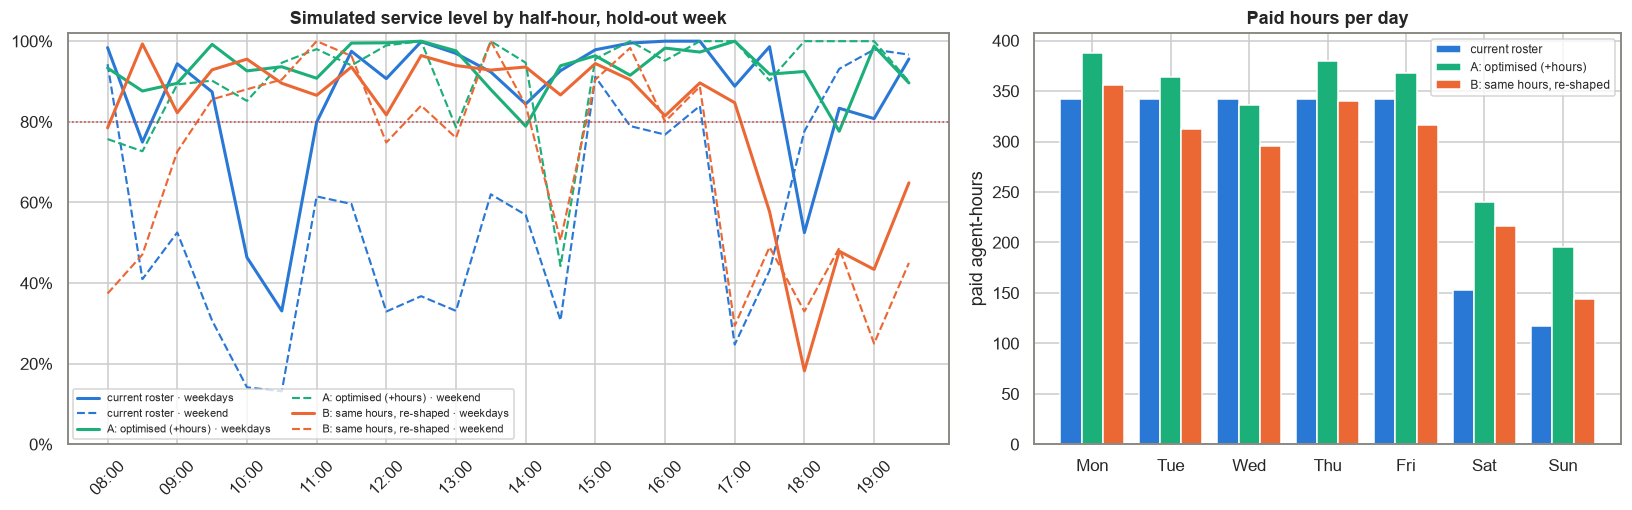

Simulator check, current roster: simulated SL 78.1% vs actual 78.2%
optimised: hours 1,980 → 2,272 (+14.7%, AZN +2,628/week); SL 78.1% → 92.7%; abandon 8.8% → 2.7%
same-hours: hours 1,980 → 1,980 (+0.0%, AZN +0/week); SL 78.1% → 83.4%; abandon 8.8% → 6.8%


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
we = np.array([d.dayofweek >= 5 for d in test.index])
STY = {"current": (BLUE, "current roster"), "optimised": (AQUA, "A: optimised (+hours)"), "same-hours": (ORANGE, "B: same hours, re-shaped")}
for s, (col, lab) in STY.items():
    m = pd.concat(sl_int[s], axis=1).values
    ax[0].plot(range(24), m[:, ~we].mean(1), color=col, lw=2, label=f"{lab} · weekdays")
    ax[0].plot(range(24), m[:, we].mean(1), color=col, ls="--", lw=1.4, label=f"{lab} · weekend")
ax[0].axhline(.8, color=RED, lw=1, ls=":"); ax[0].set_xticks(range(0, 24, 2), L[::2], rotation=45)
ax[0].yaxis.set_major_formatter(PercentFormatter(1, 0)); ax[0].set_ylim(0, 1.02)
ax[0].set_title("Simulated service level by half-hour, hold-out week"); ax[0].legend(fontsize=7, loc="lower left", ncol=2)
x = np.arange(len(cmp) - 1); w = .27
for j, (s, (col, lab)) in enumerate(STY.items()):
    ax[1].bar(x + (j - 1) * w, cmp[f"hours {s}"][:-1], w, color=col, label=lab)
ax[1].set_xticks(x, [i[:3] for i in cmp.index[:-1]]); ax[1].set_ylabel("paid agent-hours"); ax[1].set_title("Paid hours per day")
ax[1].legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.savefig("images/schedule_impact.png", bbox_inches="tight"); plt.show()
print(f"Simulator check, current roster: simulated SL {tot['SL current'] if 'SL current' in tot else tot['SL current']:.1%} vs actual {tot['SL actual']:.1%}")
for s in ["optimised", "same-hours"]:
    print(f"{s}: hours {tot['hours current']:,.0f} → {tot['hours ' + s]:,.0f} ({tot['hours ' + s] / tot['hours current'] - 1:+.1%}, "
          f"AZN {(tot['hours ' + s] - tot['hours current']) * COST_PER_HOUR:+,.0f}/week); SL {tot['SL current']:.1%} → {tot['SL ' + s]:.1%}; "
          f"abandon {tot['abandon current']:.1%} → {tot['abandon ' + s]:.1%}")

## 8. Findings & recommendations

In [18]:
wk = cmp.loc["Week"]
F = pd.DataFrame([
 ("Hidden misses", f"Headline SL {sl_all:.0%}, but {miss:.0%} of half-hours miss 80/20; weekends {by_day.service_level.iloc[5:].mean():.0%}, Tue {by_day.service_level['Tue']:.0%}",
  "Report SL per half-hour and per day, not only the monthly average; alert on any interval below 70%"),
 ("Roster shape", "Flat 08/09/11 weekday pattern: short 08:30–11:00 and at 18:00, surplus 13:00–17:00 and midweek",
  "Replace the three fixed shifts with staggered starts and 4-hour part-time peak shifts"),
 ("A: meet 80/20 everywhere", f"{wk['hours current']:,.0f} → {wk['hours optimised']:,.0f} paid h/week ({wk['hours optimised'] / wk['hours current'] - 1:+.0%}, AZN {(wk['hours optimised'] - wk['hours current']) * COST_PER_HOUR:+,.0f}/week); simulated SL {wk['SL current']:.0%} → {wk['SL optimised']:.0%}, abandon {wk['abandon current']:.1%} → {wk['abandon optimised']:.1%}",
  "Needed in billing weeks; plan the extra hours as part-time peak and weekend shifts"),
 ("B: same hours, re-shaped", f"{wk['hours same-hours']:,.0f} h/week; simulated SL {wk['SL current']:.0%} → {wk['SL same-hours']:.0%}, abandon {wk['abandon current']:.1%} → {wk['abandon same-hours']:.1%}, half-hours below 80/20: {wk['bad intervals current']:.0f} → {wk['bad intervals same-hours']:.0f}",
  "Free first step, mostly a weekend fix: move weekday afternoon hours to weekends; alone it still leaves most weak half-hours"),
 ("Billing cycle", f"Days 1–5 of the month bring {np.exp(beta[7]) - 1:+.0%} calls; naive forecast misses it",
  "Forecast with weekday + billing-day effects; lock leave and training out of days 1–5"),
 ("Outage incidents", "Two outage afternoons added +1,100 and +1,600 calls vs the same weekday a week earlier; SL collapsed for hours",
  "Push outage status to IVR / SMS within 15 minutes and keep a 'surge' list of back-office staff who can log in"),
 ("Long calls", f"Complaints and new connections take 7–8 min vs {aht_all / 60:.1f} min average",
  "Route new-connection requests to the online form / callback queue to free peak capacity"),
], columns=["Area", "Evidence", "Recommendation"])
F.style.hide()

Area,Evidence,Recommendation
Hidden misses,"Headline SL 81%, but 33% of half-hours miss 80/20; weekends 61%, Tue 76%","Report SL per half-hour and per day, not only the monthly average; alert on any interval below 70%"
Roster shape,"Flat 08/09/11 weekday pattern: short 08:30–11:00 and at 18:00, surplus 13:00–17:00 and midweek",Replace the three fixed shifts with staggered starts and 4-hour part-time peak shifts
A: meet 80/20 everywhere,"1,980 → 2,272 paid h/week (+15%, AZN +2,628/week); simulated SL 78% → 93%, abandon 8.8% → 2.7%",Needed in billing weeks; plan the extra hours as part-time peak and weekend shifts
"B: same hours, re-shaped","1,980 h/week; simulated SL 78% → 83%, abandon 8.8% → 6.8%, half-hours below 80/20: 62 → 61","Free first step, mostly a weekend fix: move weekday afternoon hours to weekends; alone it still leaves most weak half-hours"
Billing cycle,Days 1–5 of the month bring +15% calls; naive forecast misses it,Forecast with weekday + billing-day effects; lock leave and training out of days 1–5
Outage incidents,"Two outage afternoons added +1,100 and +1,600 calls vs the same weekday a week earlier; SL collapsed for hours",Push outage status to IVR / SMS within 15 minutes and keep a 'surge' list of back-office staff who can log in
Long calls,Complaints and new connections take 7–8 min vs 4.2 min average,Route new-connection requests to the online form / callback queue to free peak capacity


**Bottom line:** the problem is both *shape* and *size*. Re-shaping the same paid hours (scenario B) mainly rescues the weekends and lifts the simulated service level by about five points, but it cannot fix the weekday morning peaks: in a billing week the forecast requirement (about 2,050 hours after shrinkage) is already above today's 1,980 hours. Meeting 80/20 in nearly every half-hour (scenario A) needs about 15% more hours, mostly 4-hour part-time shifts at the peaks and on weekends. Scenario B also trades the weekday evening (17:00-20:00) for the morning peaks, because its objective weights the big peaks most, so it needs a manual review before use. Reporting only the monthly service level hid all of this.

*Caveats: Erlang C assumes Poisson arrivals and no abandonment; shrinkage is applied as one average ratio (real lunch and break planning would add constraints); the hold-out week is a billing week, so the extra hours in scenario A are a peak-week figure; the simulator uses the same queue logic that generated the synthetic data, so with real data it should first be validated against actual results, as in section 7. Agent cost (AZN 9/hour) is an assumption.*